# 1. Data cleaning & exploratory analysis

**Goal:** turn the raw UCI Adult files into one clean table and understand who earns more than $50K, before any modelling.

**Output:** `data/processed/adult_{train,test}_clean.csv` and figures in `figures/`.

## 1.1 Load the raw data
The raw files have no header, a leading space before every value, `?` for missing values, a junk first line in the test file and test labels ending in a period (see `data/README.md`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

RAW = Path("../data/raw")
PROCESSED = Path("../data/processed")
FIGURES = Path("../figures")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

COLUMNS = ["age", "workclass", "fnlwgt", "education", "education-num", "marital-status",
           "occupation", "relationship", "race", "sex", "capital-gain", "capital-loss",
           "hours-per-week", "native-country", "income"]

read = dict(names=COLUMNS, skipinitialspace=True, na_values="?")
df_train = pd.read_csv(RAW / "adult.data", **read)
df_test = pd.read_csv(RAW / "adult.test", skiprows=1, **read)
print("train:", df_train.shape, " test:", df_test.shape)
df_train.head()

train: (32561, 15)  test: (16281, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


## 1.2 Clean
### Target

In [2]:
for df in (df_train, df_test):
    df["income"] = df["income"].str.rstrip(".").map({"<=50K": 0, ">50K": 1})
    assert df["income"].notna().all()
print("Share >50K  train: %.3f   test: %.3f" % (df_train["income"].mean(), df_test["income"].mean()))

Share >50K  train: 0.241   test: 0.236


### Duplicates

In [3]:
n_dup = df_train.duplicated().sum()
print(f"Exact duplicate rows in train: {n_dup} ({n_dup / len(df_train):.2%})")
df_train = df_train.drop_duplicates().reset_index(drop=True)

Exact duplicate rows in train: 24 (0.07%)


There are 24 exact duplicates (0.07%). Because the rows include `fnlwgt`, a continuous sampling weight, two genuinely different people are very unlikely to match on every column, so these are almost certainly data-entry duplicates. I drop them from the training set only; the test set is left untouched so results stay comparable with other work on this dataset.

### Missing values

In [4]:
missing = df_train.isna().sum()
print(missing[missing > 0])
print()
for col in ["workclass", "occupation", "native-country"]:
    rate_missing = df_train.loc[df_train[col].isna(), "income"].mean()
    rate_present = df_train.loc[df_train[col].notna(), "income"].mean()
    print(f"{col:15s}  share >50K when missing: {rate_missing:.3f}   when present: {rate_present:.3f}")
print("\nRows missing workclass that also miss occupation:",
      (df_train["workclass"].isna() & df_train["occupation"].isna()).sum())

workclass         1836
occupation        1843
native-country     582
dtype: int64

workclass        share >50K when missing: 0.104   when present: 0.249
occupation       share >50K when missing: 0.104   when present: 0.249
native-country   share >50K when missing: 0.251   when present: 0.241

Rows missing workclass that also miss occupation: 1836


Missingness is **not random**: people with a missing `workclass`/`occupation` earn >50K far less often (10% vs 25%), and the two are missing together (the 7 extra missing occupations are people who never worked). Dropping these rows would remove a distinctive low-income group and bias the data, and imputing the most common value would hide the signal. So I keep the rows and treat missing as its own category, `"Unknown"`. Missing `native-country` is unrelated to income, but the same treatment is harmless.

`native-country` has 40 values, most with only a few dozen people, so I group it into United-States / Other / Unknown.

In [5]:
for df in (df_train, df_test):
    df[["workclass", "occupation", "native-country"]] = df[["workclass", "occupation", "native-country"]].fillna("Unknown")
    # 40 countries, most with a handful of rows: keep the US and group the rest
    df["native-country"] = df["native-country"].where(df["native-country"].isin(["United-States", "Unknown"]), "Other")
print(df_train["native-country"].value_counts())

native-country
United-States    29153
Other             2802
Unknown            582
Name: count, dtype: int64


### Redundant and non-personal columns

In [6]:
print(pd.crosstab(df_train["education"], df_train["education-num"]).astype(bool).sum(axis=1).max(),
      "education-num value(s) per education level")
for df in (df_train, df_test):
    df.drop(columns=["education", "fnlwgt"], inplace=True)

1 education-num value(s) per education level


- `education` and `education-num` are a one-to-one mapping, so I keep only the numeric version, which also preserves the ordering of education levels.
- `fnlwgt` is a census sampling weight (how many people in the population a row represents), not a property of the person, so it is not used as a feature.

## 1.3 Explore
### How imbalanced is the target?

In [7]:
base = df_test["income"].mean()
print(f"Share >50K in test set: {base:.1%}")
print(f"Accuracy of always predicting <=50K: {1 - base:.1%}")

Share >50K in test set: 23.6%
Accuracy of always predicting <=50K: 76.4%


Only about 1 in 4 people earn >50K. A model that always says "<=50K" already reaches 76% accuracy, so accuracy alone is a weak measure here; notebook 2 also reports precision, recall and ROC AUC.

### Income by sex and race

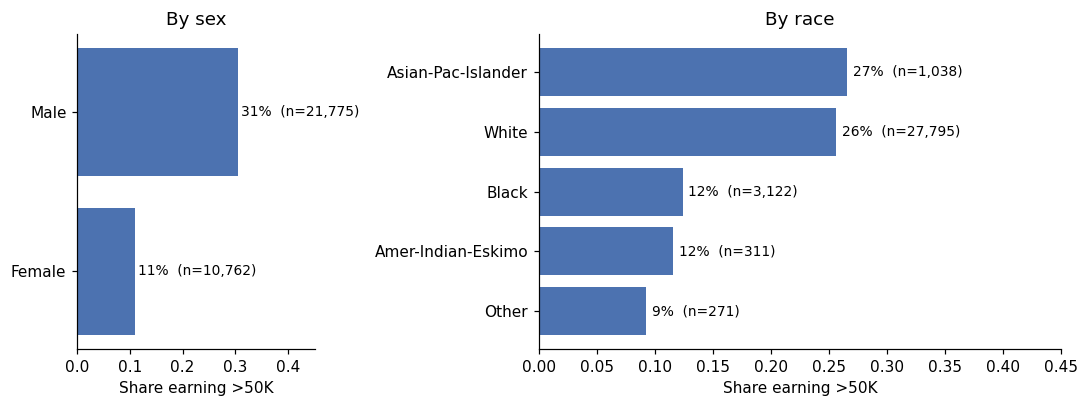

race    Asian-Pac-Islander  Black  Other  White
sex                                            
Female               0.124  0.058  0.079  0.119
Male                 0.337  0.190  0.121  0.318


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), gridspec_kw={"width_ratios": [1, 2.2]})
for ax, col in zip(axes, ["sex", "race"]):
    stats = df_train.groupby(col)["income"].agg(["mean", "size"]).sort_values("mean")
    ax.barh(stats.index, stats["mean"], color="#4C72B0")
    for i, (m, n) in enumerate(zip(stats["mean"], stats["size"])):
        ax.text(m + 0.005, i, f"{m:.0%}  (n={n:,})", va="center", fontsize=9)
    ax.set_xlim(0, 0.45)
    ax.set_xlabel("Share earning >50K")
    ax.set_title(f"By {col}")
plt.tight_layout()
plt.savefig(FIGURES / "income_by_group.png", bbox_inches="tight")
plt.show()

print(pd.crosstab([df_train["sex"]], df_train["race"].where(df_train["race"].isin(["White", "Black", "Asian-Pac-Islander"]), "Other"),
                  values=df_train["income"], aggfunc="mean").round(3))

The gaps in the raw data are large:
- **Sex:** 31% of men earn >50K vs 11% of women, almost a 3x difference.
- **Race:** White and Asian-Pacific-Islander people earn >50K about twice as often as Black people.
- **Intersection:** the gaps compound. Black women have the lowest rate (6%), while white and Asian-Pacific-Islander men have the highest (32-34%), more than five times as high.

These are differences in the *data*, which reflect 1994 labour-market inequalities. A model trained on this data will learn them. Notebook 3 measures whether the model also makes *errors* unequally across groups.

The Amer-Indian-Eskimo and Other categories have only about 300 people each, so from here on they are merged into one "Other" group (about 580 people), which keeps group metrics from being dominated by noise.

### Which features are related to income?

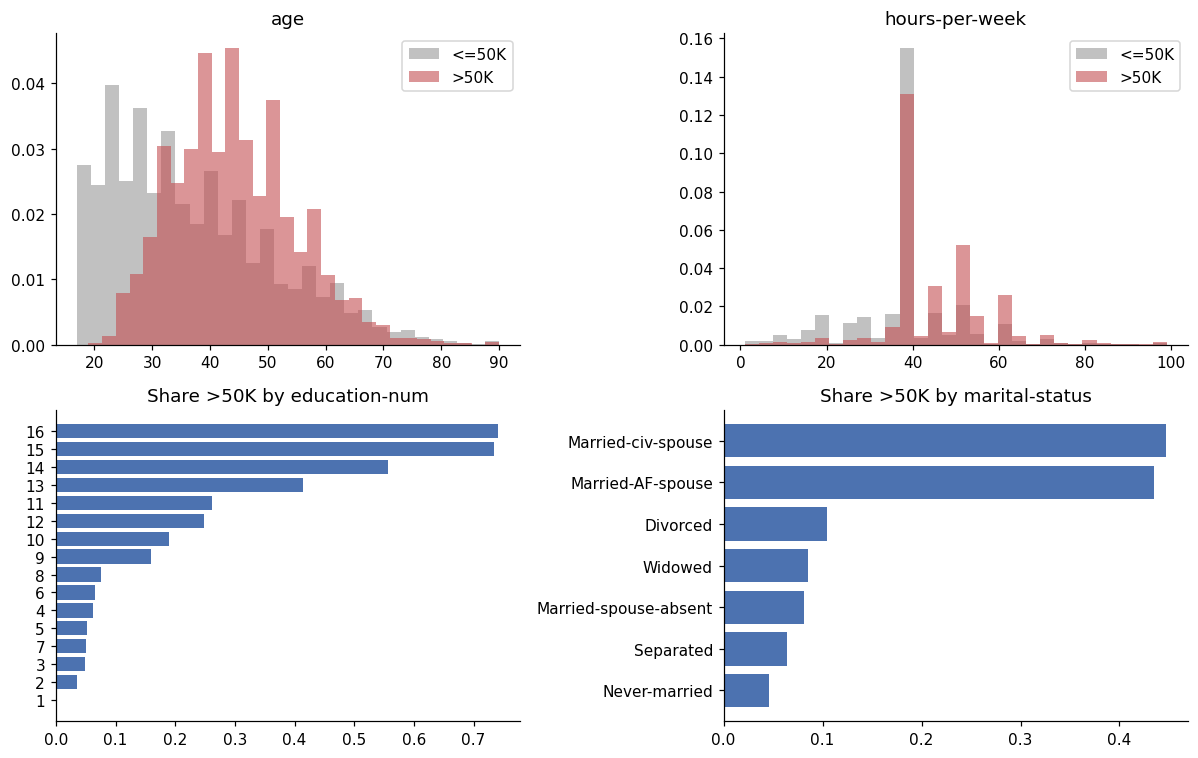

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes[0], ["age", "hours-per-week"]):
    for y, c in [(0, "#999999"), (1, "#C44E52")]:
        ax.hist(df_train.loc[df_train["income"] == y, col], bins=30, alpha=0.6, density=True, color=c,
                label=">50K" if y else "<=50K")
    ax.set_title(col)
    ax.legend()
for ax, col in zip(axes[1], ["education-num", "marital-status"]):
    rate = df_train.groupby(col)["income"].mean().sort_values()
    ax.barh(rate.index.astype(str), rate.values, color="#4C72B0")
    ax.set_title(f"Share >50K by {col}")
plt.tight_layout()
plt.savefig(FIGURES / "income_drivers.png", bbox_inches="tight")
plt.show()

In [10]:
occ = df_train.groupby("occupation")["income"].agg(["mean", "size"]).sort_values("mean", ascending=False)
occ.round(3)

,mean,size
occupation,,
Exec-managerial,0.484,4065
Prof-specialty,0.449,4136
Protective-serv,0.325,649
Tech-support,0.305,927
Sales,0.269,3650
Craft-repair,0.227,4094
Transport-moving,0.200,1597
Adm-clerical,0.135,3768
Machine-op-inspct,0.124,2000


- **Age:** high earners are concentrated between 35 and 60.
- **Hours:** high earners work more hours; the <=50K group has a large spike at exactly 40 and many part-timers.
- **Education:** the share >50K rises steadily with education, to over 70% for Prof-school and Doctorate.
- **Marital status:** married people (civilian spouse) earn >50K about 45% of the time, vs under 10% for most other categories. This is the strongest single signal, and it is linked to sex through `relationship` (see below).
- **Occupation:** executive/managerial and professional jobs are at about 45-48%, service and cleaning jobs below 7%.

### Proxy check: which features reveal sex or race?
If a feature predicts the sensitive attribute well, a model can pick up sex or race through it even after `sex` and `race` are dropped.

In [11]:
def proxy_strength(df, feature, target):
    """How well `feature` alone predicts `target` (majority class per feature value), vs. predicting the overall majority."""
    acc = df.groupby(feature)[target].agg(lambda s: s.value_counts(normalize=True).iloc[0])
    weights = df[feature].value_counts(normalize=True)
    return (acc * weights).sum(), df[target].value_counts(normalize=True).iloc[0]

rows = []
for f in ["relationship", "marital-status", "occupation", "workclass", "native-country"]:
    for target in ["sex", "race"]:
        acc, baseline = proxy_strength(df_train, f, target)
        rows.append({"feature": f, "predicts": target, "accuracy": acc, "baseline": baseline, "gain": acc - baseline})
pd.DataFrame(rows).sort_values("gain", ascending=False).round(3)

,feature,predicts,accuracy,baseline,gain
0,relationship,sex,0.775,0.669,0.105
2,marital-status,sex,0.724,0.669,0.055
4,occupation,sex,0.723,0.669,0.053
3,marital-status,race,0.854,0.854,0.000
9,native-country,race,0.854,0.854,0.000
1,relationship,race,0.854,0.854,0.000
5,occupation,race,0.854,0.854,0.000
6,workclass,sex,0.669,0.669,0.000
7,workclass,race,0.854,0.854,0.000
8,native-country,sex,0.669,0.669,0.000


In [12]:
pd.crosstab(df_train["relationship"], df_train["sex"])

sex,Female,Male
relationship,,
Husband,1,13186
Not-in-family,3869,4423
Other-relative,430,551
Own-child,2243,2821
Unmarried,2653,792
Wife,1566,2


`relationship` is a near-perfect proxy for sex: "Husband" is almost always male and "Wife" almost always female. `marital-status` and `occupation` also carry some information about sex. For race, no single feature is a strong proxy by this simple measure, because race is so imbalanced (85% White) that guessing "White" is already 85% accurate.

This matters in notebook 3: **simply deleting the `sex` column will not stop a model from treating men and women differently**, because `relationship` encodes it anyway.

**Who is in the data?** The crosstab also shows a sampling issue: there are 13,187 husbands but only 1,568 wives, so the data mostly includes one person per married couple, usually the husband. As a result, most women in the data are never-married, divorced or widowed, groups with lower incomes in general. Part of the gap between men and women (31% vs 11%) therefore reflects who was sampled, not only the labour market. This is also why `relationship` and `marital-status` work as proxies for sex. The dataset documentation does not explain how the records were selected.

## 1.4 Save

In [13]:
df_train.to_csv(PROCESSED / "adult_train_clean.csv", index=False)
df_test.to_csv(PROCESSED / "adult_test_clean.csv", index=False)
print("saved", df_train.shape, df_test.shape)

saved (32537, 13) (16281, 13)


## Summary

- Cleaned 32,537 training and 16,281 test rows: fixed labels, dropped 24 duplicates, kept missing values as an explicit `"Unknown"` category because missingness predicts low income.
- The target is imbalanced (24% earn >50K), so accuracy must be read against a 76% "always <=50K" baseline.
- Income is driven mostly by marital status, education, occupation, age and hours worked.
- There are large income gaps by sex (31% vs 11%) and race, and they compound at the intersection.
- `relationship` is a proxy for sex, so removing the sensitive columns alone cannot guarantee a sex-blind model.
- The data mostly includes one person per married couple (8 times as many husbands as wives), so part of the gender gap reflects who was sampled.